In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from keras.models import Sequential
from keras.layers import Dense,Dropout
from keras.callbacks import EarlyStopping

In [103]:
df=pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [104]:
df.shape

(20640, 10)

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [106]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [107]:
df.dropna(inplace=True)

In [108]:
df.sample(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
6016,-117.78,34.06,33.0,1056.0,272.0,964.0,300.0,2.4464,128700.0,INLAND
10811,-117.92,33.64,24.0,2539.0,695.0,1623.0,611.0,3.0708,188700.0,<1H OCEAN
16631,-120.84,35.32,15.0,2419.0,538.0,1279.0,522.0,3.4762,189600.0,NEAR OCEAN
15086,-116.92,32.81,23.0,2668.0,528.0,1510.0,524.0,3.3669,158900.0,<1H OCEAN
19369,-123.02,38.36,16.0,1496.0,298.0,778.0,284.0,3.8589,268800.0,NEAR OCEAN


In [109]:
df.shape

(20433, 10)

In [110]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [111]:
df['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9034
INLAND,6496
NEAR OCEAN,2628
NEAR BAY,2270
ISLAND,5


In [112]:
df['ocean_proximity']=df['ocean_proximity'].map({'<1H OCEAN':0,'INLAND':1,'NEAR OCEAN':2,'NEAR BAY':3,'ISLAND':4})

In [113]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,1
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,1
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,1
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,1
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,1


In [114]:
x=df.drop('median_house_value',axis=1)
y=df['median_house_value']

In [115]:
x=np.array(x)
y=np.array(y)

In [116]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [117]:
print(x.shape,X_train.shape,X_test.shape)

(20433, 9) (14303, 9) (6130, 9)


In [118]:
minmax=MinMaxScaler()
x_train_scaled=minmax.fit_transform(X_train)
x_test_scaled=minmax.transform(X_test)

In [119]:
x_train_scaled

array([[0.34311741, 0.53878852, 0.43137255, ..., 0.13402401, 0.09961932,
        0.25      ],
       [0.62044534, 0.15302869, 0.64705882, ..., 0.12086828, 0.08059199,
        0.        ],
       [0.24392713, 0.50371945, 0.50980392, ..., 0.07054761, 0.31601633,
        0.        ],
       ...,
       [0.60020243, 0.15621679, 0.80392157, ..., 0.05936524, 0.1792458 ,
        0.        ],
       [0.23380567, 0.53453773, 0.21568627, ..., 0.17365565, 0.33020234,
        0.75      ],
       [0.19433198, 0.55154091, 1.        , ..., 0.10623253, 0.23403125,
        0.75      ]], shape=(14303, 9))

In [120]:
model=Sequential()
model.add(Dense(1000,input_shape=[X_train.shape[1],],activation='relu'))
model.add(Dense(500,activation='relu'))
model.add(Dense(250,activation='relu'))
model.add(Dense(1,activation='linear'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [121]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 1000)           │        10,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 500)            │       500,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 250)            │       125,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │           251 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,001 (2.43 MB)

 Trainable params: 636,001 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

In [122]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),

    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    x_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 55806681088.0000 - mae: 206124.1250 - val_loss: 53119692800.0000 - val_mae: 199641.6875
Epoch 2/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 41086713856.0000 - mae: 166128.8594 - val_loss: 24004339712.0000 - val_mae: 114689.3906
Epoch 3/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 15273238528.0000 - mae: 92102.3828 - val_loss: 12491972608.0000 - val_mae: 87779.8906
Epoch 4/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12191561728.0000 - mae: 87411.7578 - val_loss: 12197780480.0000 - val_mae: 87623.2969
Epoch 5/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 11882748928.0000 - mae: 86675.1328 - val_loss: 11915678720.0000 - val_mae: 86385.1406
Epoch 6/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 11577321472.0000 - mae: 85504.7578 - val_loss: 11632173056.0000 - val_mae: 85615.4297
Epoch 7/100
358/358 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 11270786048.0000 - mae: 84476.7344 - val_loss: 113399

In [135]:
y_pred=model.predict(x_test_scaled)

192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [136]:
y_pred

array([[179046.72 ],
       [147103.72 ],
       [198603.45 ],
       ...,
       [135646.95 ],
       [ 65447.543],
       [101108.9  ]], shape=(6130, 1), dtype=float32)

In [125]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_log_error,mean_squared_error

In [126]:
print(mean_absolute_error(y_test,y_pred))

48344.578112095995


In [127]:
print(mean_squared_error(y_test,y_pred))

4535962950.535576


In [128]:
print(mean_squared_log_error(y_test,y_pred))


0.11495472552692151


In [129]:
print(r2_score(y_test,y_pred))

0.6597415093226053


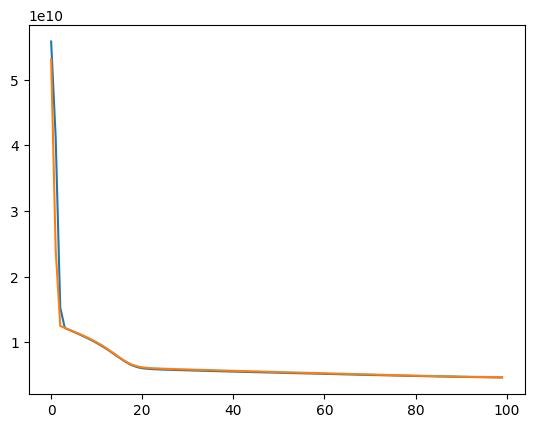

In [130]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

In [131]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training shape: (14303, 9)
Testing shape: (6130, 9)
Training target: (14303,)
Testing target: (6130,)


In [132]:
import pandas as pd

comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred.flatten()
})

print(comparison.head(10))

     Actual      Predicted
0  245800.0  179046.718750
1  137900.0  147103.718750
2  218200.0  198603.453125
3  220800.0  154549.953125
4  170500.0  182159.203125
5   75000.0  103621.570312
6  269400.0  276431.187500
7  228900.0  249917.500000
8  500001.0  397931.281250
9   80800.0   78623.109375


In [133]:
import numpy as np
import pandas as pd

print("Actual values:")
print(pd.Series(y_test).describe())

print("\nPredicted values:")
print(pd.Series(np.array(y_pred).flatten()).describe())

print("\nFirst 10 predictions:")
print(pd.DataFrame({
    "Actual": np.array(y_test).flatten()[:10],
    "Predicted": np.array(y_pred).flatten()[:10]
}))

Actual values:
count      6130.000000
mean     205885.445840
std      115469.075929
min       14999.000000
25%      119400.000000
50%      177300.000000
75%      265500.000000
max      500001.000000
dtype: float64

Predicted values:
count      6130.000000
mean     204160.000000
std       91192.203125
min        2095.878906
25%      137181.203125
50%      192180.203125
75%      254350.496094
max      741575.000000
dtype: float64

First 10 predictions:
     Actual      Predicted
0  245800.0  179046.718750
1  137900.0  147103.718750
2  218200.0  198603.453125
3  220800.0  154549.953125
4  170500.0  182159.203125
5   75000.0  103621.570312
6  269400.0  276431.187500
7  228900.0  249917.500000
8  500001.0  397931.281250
9   80800.0   78623.109375


In [134]:
model.save('model_ann.h5')

import pickle
pickle.dump(minmax,open('min_max_scaler.pkl','wb'))